load the model and run on an image

In [1]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")   # downloads automatically (~6 MB)
results = model("https://ultralytics.com/images/bus.jpg")
r = results[0]

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\ADMIN\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

image 1/1 e:\ppe-safety-detector\notebooks\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 166.9ms
Speed: 4.5ms preprocess, 166.9ms inference, 3.5ms postprocess per image at shape (1, 3, 640, 480)


understand the output format

In [2]:
print("Class names:", r.names)
for box in r.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    print(f"{r.names[cls_id]:10s} conf={conf:.2f} box=({x1:.0f},{y1:.0f},{x2:.0f},{y2:.0f})")

Class names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone'

view the annotated image

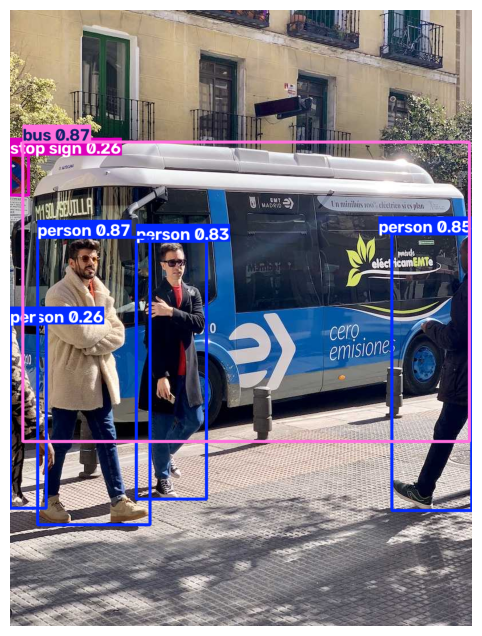

In [3]:
plt.figure(figsize=(8, 8))
plt.imshow(r.plot()[:, :, ::-1])   # BGR -> RGB
plt.axis("off")
plt.show()

test your webcam


0: 480x640 1 person, 1 handbag, 166.6ms
Speed: 3.5ms preprocess, 166.6ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)


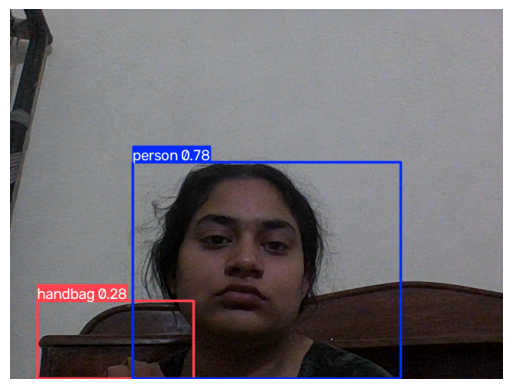

In [4]:
import cv2
cap = cv2.VideoCapture(0)
ok, frame = cap.read()
cap.release()
if ok:
    res = model(frame)[0]
    plt.imshow(res.plot()[:, :, ::-1]); plt.axis("off"); plt.show()
else:
    print("No webcam found, that's fine, we'll use video files.")